In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Carga del dataset
df = pd.read_csv('dataset_segmentacion_clientes.csv')

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (700, 7)


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


La base cargó con éxito y cuenta con 700 filas y 7 columnas

In [2]:
# Verificamos si existen nulos
print("Nulos por columna:")
print(df.isnull().sum())

# Definimos las 5 variables de comportamiento de clientes
features = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity',
    'returns_rate'
]

# Revisamos las escalas para ver la diferencia de magnitudes
df[features].describe().T[['min', 'mean', 'max', 'std']].round(2)

Nulos por columna:
purchase_freq_month     0
avg_basket_usd          0
time_on_site_min        0
discount_sensitivity    0
returns_rate            0
noise_gauss             0
noise_uniform           0
dtype: int64


,min,mean,max,std
purchase_freq_month,0.10,5.88,14.60,4.47
avg_basket_usd,86.99,248.17,452.97,154.90
time_on_site_min,3.16,16.78,38.35,12.91
discount_sensitivity,0.00,0.43,1.00,0.43
returns_rate,0.00,0.34,0.80,0.36


No se registran valores nulos en el conjunto de datos. Al revisar las estadísticas descriptivas, se evidencia una gran disparidad de escalas,mientras que discount_sensitivity varía entre 0.00 y 1.00, avg_basket_usd maneja valores con un promedio de 248.17 USD y un máximo de 452.97 USD.

In [3]:
# Escalamos las variables para que el ticket en dolares no distorsione las distancias euclidianas
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

print("Forma de la matriz escalada:", X_scaled.shape)

Forma de la matriz escalada: (700, 5)


Se aplicó StandardScaler sobre las 5 variables seleccionadas para dejarlas a todas en una misma escala y evitar que los montos en dólares dominen el cálculo de distancias del algoritmo. La matriz resultante tiene 700 filas y 5 columnas. 

k = 2 -> Inercia: 2088.88
k = 3 -> Inercia: 1408.70
k = 4 -> Inercia: 1173.44
k = 5 -> Inercia: 997.74
k = 6 -> Inercia: 762.47


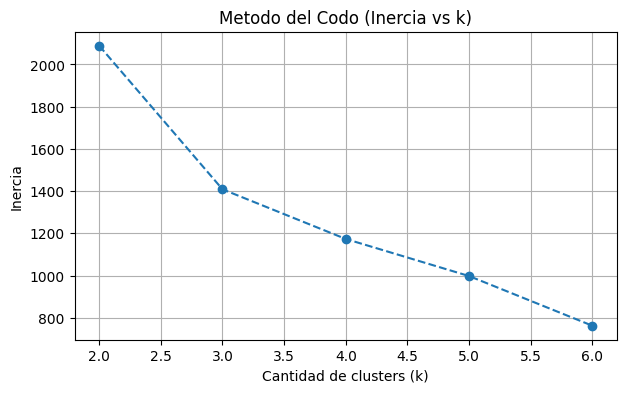

In [4]:
# Calculamos la inercia para k entre 2 y 6 para aplicar el metodo del codo
inercia = []
k_valores = range(2, 7)

for k in k_valores:
    modelo = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    modelo.fit(X_scaled)
    inercia.append(modelo.inertia_)
    print(f"k = {k} -> Inercia: {modelo.inertia_:.2f}")

# Graficamos la curva de inercia
plt.figure(figsize=(7, 4))
plt.plot(k_valores, inercia, marker='o', linestyle='--')
plt.title('Metodo del Codo (Inercia vs k)')
plt.xlabel('Cantidad de clusters (k)')
plt.ylabel('Inercia')
plt.grid(True)
plt.show()

La curva de inercia presenta un quiebre notorio en k = 3 (inercia de 1408.70), punto a partir del cual la caída se vuelva mas lenta. 

In [5]:
# Entrenamos el modelo definitivo con k=3 segun el punto de quiebre del codo
k_optimo = 3
kmeans = KMeans(n_clusters=k_optimo, init='k-means++', random_state=42, n_init=10)

# Asignamos el cluster a cada cliente
df['cluster'] = kmeans.fit_predict(X_scaled)

# Distribucion de clientes por grupo
print("Cantidad de clientes por cluster:")
print(df['cluster'].value_counts())

# Promedios reales de cada variable por cluster para interpretar los perfiles
perfiles = df.groupby('cluster')[features].mean().round(2)
print("\nPerfiles promedio de cada grupo (escala original):")
perfiles

Cantidad de clientes por cluster:
cluster
1    250
0    230
2    220
Name: count, dtype: int64

Perfiles promedio de cada grupo (escala original):


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
cluster,,,,,
0,11.96,180.00,35.02,0.54,0.33
1,1.85,450.12,5.97,0.36,0.38
2,4.09,89.96,10.00,0.38,0.30


Interpretación de los 3 perfiles obtenidos:
* **Cluster 0 (230 clientes):**  Compran 12 veces al mes, pasan 35 minutos en el sitio, tienen un ticket medio de 180 USD y alta sensibilidad a descuentos (0.54).
* **Cluster 1 (250 clientes):** Frecuencia baja (1.8 compras/mes) y permanencia corta (6 min), pero con el gasto promedio más alto (450 USD).
* **Cluster 2 (220 clientes):**  Frecuencia moderada (4 compras/mes), 10 minutos de navegación y el ticket promedio más bajo (90 USD).